### *Algoritmos Genéticos y Optimización Heurística - UTN-FRT*

# **Trabajo Práctico N°1**
### Tema: Hill Climbing

***Integrantes***

*   Breslauer, León - 56340
*   Perez, Francisco - 56355



## Ejercicio 1
El siguiente código es una implementación simple del algoritmo Hill Climbing, al cual le faltan algunas líneas para funcionar correctamente. Su trabajo consiste en completar el código y probar el algoritmo con una función de prueba (Benchmark).

In [2]:
# Importar funciones declaradas en el archivo helper.
from helper_hill_climbing import validate_inputs, graficarCaminata, graficarEvolucionFitness

La siguiente función calcula un nuevo punto de exploración a partir de un vector solución dado. La función es utilizada en el método de Hill Climbing.

In [3]:
def puntoExploracion(X0, max_eps):
    """Calcular un nuevo punto de exploración o solución, a partir de
    una solución previa.

    Parameters
    ----------
    X0: list
        Vector solucion inicial.
    max_eps: float
        Valor del tamaño máximo del paso.

    Returns
    -------
    X : list
        Vector solución generado.
    R : list
        Vector dirección.
    """

    # Formación de vector de avance R
    R = [2 * random.random() - 1 for _ in X0]
    norm = math.sqrt(sum([r_i**2 for r_i in R]))

    # Normalización del vector de avance para que sea unitario
    R = [r_i / norm for r_i in R] if norm > 0 else R

    # Generación de paso aleatorio y formación de nuevo punto de solución X
    eps = random.random() * max_eps
    X = [x0_i + eps * r_i for x0_i, r_i in zip(X0, R)]

    return X, R

In [4]:
import random
import math

def HillClimbing(fitness, X_mejor, max_eps, bounds, cant_iterac):
    """Algoritmo de Hill Climbing.

    Parameters:
    -----------
    fitness : function
        Funcion de evaluacion a optimizar
    X_mejor: list
        Vector solucion inicial, desde donde parte la exploracion.
    max_eps: float
        Valor de distancia maxima del paso a recorrer en cada iteracion.
    bounds: list(tuple)
        Matriz de tamano nx2, donde n es la cantidad de variables que
        tiene el problema (cantidad de coordenadas del vector solución).
        En la primera columna se establecen los valores limites inferiores y
        en la segunda columna se establece los valores limite superiores.
        Observen que los valores de la primera columna siempre deben ser
        menores que los de la segunda).
    cant_iterac: integer
        Cantidad de iteraciones usada como condicion de terminacion.

    Return:
    -------
    X_mejor : list
        Vector solución correspondiente a la mejor solución encontrada.
    fX_mejor : list
        Valor de evaluación de la mejores solución encontrada.
    Trace_R : list
        Lista con los vectores dirección calculados en cada iteración.
    Trace_X : list
        Lista con las soluciones calculadas en cada iteración.
    Trace_X_mejor : list
        Lista con las mejores soluciones de cada iteración.
    Trace_f : list
        Lista con los valores de evaluación de la mejor y peor solución.
    """

    fX_mejor = 0
    Trace_R = []
    Trace_X = []
    Trace_X_mejor = []
    Trace_f = []

    if not validate_inputs(X_mejor, bounds, cant_iterac, max_eps):
        return X_mejor, fX_mejor, Trace_R, Trace_X, Trace_X_mejor, Trace_f

    # evaluacion inicial
    fX_mejor = fitness(X_mejor)

    # inicializar variables
    Trace_R.append([0 for xi in X_mejor])
    Trace_X.append(X_mejor)
    Trace_X_mejor.append(X_mejor)
    Trace_f.append((fX_mejor,fX_mejor))
    it = 0
    cnt = 0
    sigue = True

    # repetir hasta que se cumpla la condicion de terminacion
    while sigue:
        #  calculo el punto de exploracion
        X, R = puntoExploracion(X_mejor, max_eps)

        # verifico y corrijo que X este dentro del dominio
        for i, xi in enumerate(X):
            X[i] = bounds[i][0] if xi < bounds[i][0] else xi
            X[i] = bounds[i][1] if xi > bounds[i][1] else xi

        # evaluo solucion
        fX0 = fX_mejor
        fX = fitness(X)

        # si la solucion actual es mejor que la que ya tenía
        if fX >= fX_mejor:
            X_mejor = X
            fX_mejor = fX
            cnt = 0
        else:
            cnt = cnt + 1

        # condicion de terminacion
        if cnt > cant_iterac:
            sigue = False

        # guardo valores para analisis posterior
        Trace_R.append(R)
        Trace_X.append(X)
        Trace_X_mejor.append(X_mejor)
        Trace_f.append((max(fX, fX0), min(fX, fX0)))

        # incremento el tiempo
        it = it + 1

        # imprimir solo si obtuve una mejor solucion
        if fX >= fX0:
            print("It.{0}: {1} -> {2}".format(it,
                [round(xi,2) for xi in X], round(fX_mejor,4)))

    print(X_mejor, fX_mejor)

    return X_mejor, fX_mejor, Trace_R, Trace_X, Trace_X_mejor, Trace_f

Probar el algoritmo con el siguiente fragmento de código:

It.1: [5] -> -25
It.2: [5.0] -> -24.9641
It.3: [4.99] -> -24.9141
It.4: [4.99] -> -24.8504
It.6: [4.98] -> -24.7516
It.8: [4.97] -> -24.6961
It.9: [4.96] -> -24.6143
It.10: [4.95] -> -24.5386
It.11: [4.95] -> -24.4806
It.12: [4.94] -> -24.4107
It.13: [4.94] -> -24.3932
It.16: [4.93] -> -24.3184
It.17: [4.92] -> -24.2443
It.18: [4.92] -> -24.1873
It.22: [4.91] -> -24.1092
It.24: [4.91] -> -24.0863
It.25: [4.91] -> -24.0705
It.26: [4.9] -> -24.044
It.27: [4.9] -> -24.0196
It.31: [4.9] -> -23.9933
It.36: [4.9] -> -23.9774
It.37: [4.9] -> -23.972
It.43: [4.89] -> -23.8925
It.44: [4.88] -> -23.7976
It.46: [4.87] -> -23.7604
It.48: [4.87] -> -23.7311
It.49: [4.87] -> -23.6834
It.53: [4.86] -> -23.6487
It.54: [4.86] -> -23.6043
It.57: [4.86] -> -23.5881
It.58: [4.85] -> -23.4995
It.59: [4.84] -> -23.4329
It.62: [4.83] -> -23.3623
It.63: [4.83] -> -23.2952
It.64: [4.83] -> -23.2919
It.65: [4.82] -> -23.2794
It.66: [4.82] -> -23.2184
It.68: [4.82] -> -23.1843
It.69: [4.81] -> -23.1622
It.73: [4

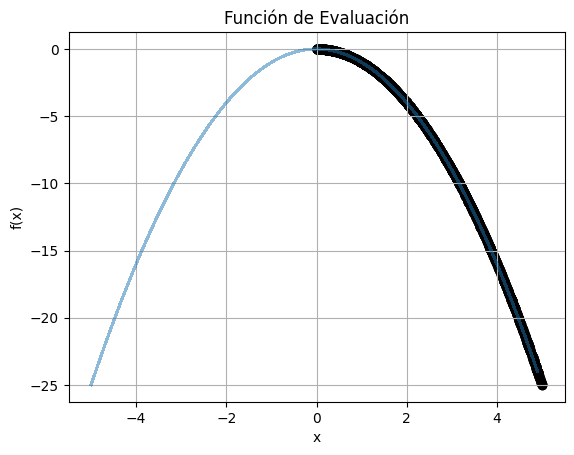

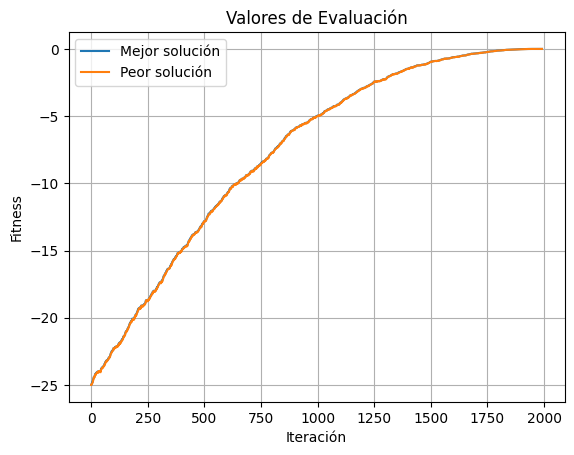

In [5]:
def parabola(x_vars):
    return -sum([x**2 for x in x_vars])

n_variables = 1
bounds = [(-5,5) for i in range(n_variables)]
x0 = [row[1] for row in bounds] # punto inicial en una de las esquinas
max_eps = 0.01
cant_iterac = 20
resolution_grafico = 0.1

X_mejor, fX_mejor, Trace_R, Trace_X, Trace_X_mejor, Trace_f = HillClimbing(
    parabola, x0, max_eps, bounds, cant_iterac)

print("-----")
print("Solución: {0}".format(X_mejor))
print("Fitness: {0}".format(fX_mejor))
print("Iteraciones: {0}".format(len(Trace_X)-1))

graficarCaminata(parabola, Trace_X_mejor, bounds, resolution_grafico)
graficarEvolucionFitness(Trace_f)

## Ejercicio 2
Contestar las siguientes preguntas:
1.    ¿El algoritmo proporcionado está diseñado para buscar el máximo o el mínimo de la función?
2.    Explicar con sus palabras en qué consiste la condición de terminación propuesta.

***Respuestas***
1. El algoritmo está diseñado para buscar el **máximo** de la función. Esto se puede ver en el bucle principal de la función HillClimbing, en la siguiente condición para actualizar la solución:
```
if fX >= fX_mejor:
    X_mejor = X
    fX_mejor = fX
```
- Esto anterior significa que el algoritmo solo acepta y se desplaza hacia un nuevo punto ***X*** si su valor de evaluación es mayor o igual al que ya poseía (`fX >= fX_mejor`).

2. La condición de terminación propuesta consiste en detener la búsqueda tras transcurrir una cantidad N (`cant_iterac`) de **iteraciones consecutivas sin logar ninguna mejora en el fitness**. Para ello, se usa un contador de intentos fallidos (`cnt`), y cada vez que se explora una solución y esta no supera el valor actual (`fX < fX_mejor`), el contador se incrementa en uno (`cnt = cnt + 1`). Si en algún momento se encuentra una solución que mejora o iguala el fitness, el contador se reinicio a cero (`cnt = 0`). Por último, el bucle finaliza cuando el contador supera el umbral fijado (`cnt > cant_iterac`)

## Ejercicio 3

Reutilizando el código anterior, compruebe el funcionamiento del algoritmo buscando un óptimo local en los siguientes casos:
1.   F(x, y) = -x^2 - y^2, x, y ∈ [-5, 5]
2.   g(x)= -0.01 x^2 - cos(2x), x ∈ [-4𝜋, 4𝜋]
3.   G(x, y) = -0.01(x^2+y^2)-cos(2x)-cos(2y), x,y ∈ [-4𝜋, 4𝜋]

En cada caso se pide:
1.   Ajuste adecuadamente los parámetros del algoritmo (tamaño máximo del paso y cantidad de iteraciones), de manera de asegurar que encuentre un óptimo local independientemente de cuál sea el punto inicial, en más del 80% de las ejecuciones. Considere dos cifras decimales de precisión para determinar que llegó al óptimo.
2.    Genere un gráfico con la “caminata” realizada, es decir donde se muestre todos los puntos por donde el algoritmo fue explorando, desde el punto inicial hasta llegar a la solución final.
3.    Generar un gráfico con los valores de fitness de las soluciones encontradas en cada iteración del algoritmo.

It.1: [-1.17, -3.69] -> -14.9557
It.3: [-1.15, -3.59] -> -14.2067
It.8: [-1.03, -3.61] -> -14.0812
It.11: [-1.1, -3.5] -> -13.4743
It.14: [-0.97, -3.53] -> -13.3996
It.16: [-0.83, -3.56] -> -13.3394
It.17: [-0.84, -3.41] -> -12.3265
It.20: [-0.85, -3.35] -> -11.9365
It.22: [-0.83, -3.33] -> -11.7483
It.24: [-0.85, -3.3] -> -11.6224
It.27: [-0.96, -3.24] -> -11.4416
It.28: [-0.92, -3.06] -> -10.1917
It.29: [-1.09, -2.96] -> -9.9381
It.30: [-0.95, -2.94] -> -9.5229
It.33: [-0.85, -2.95] -> -9.4574
It.35: [-0.8, -2.86] -> -8.8082
It.37: [-0.68, -2.8] -> -8.3017
It.39: [-0.76, -2.71] -> -7.9408
It.47: [-0.77, -2.7] -> -7.8993
It.48: [-0.84, -2.67] -> -7.8446
It.50: [-0.8, -2.61] -> -7.438
It.53: [-0.78, -2.6] -> -7.3583
It.54: [-0.73, -2.54] -> -7.0081
It.57: [-0.61, -2.44] -> -6.3412
It.58: [-0.58, -2.4] -> -6.1114
It.59: [-0.58, -2.4] -> -6.1109
It.60: [-0.54, -2.33] -> -5.6994
It.61: [-0.43, -2.31] -> -5.5293
It.66: [-0.61, -2.23] -> -5.3612
It.68: [-0.63, -2.18] -> -5.1696
It.69: [-0.6

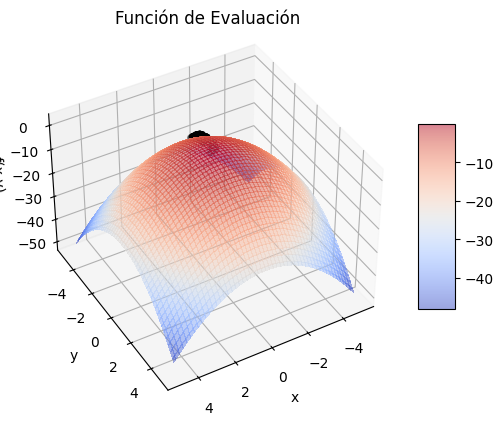

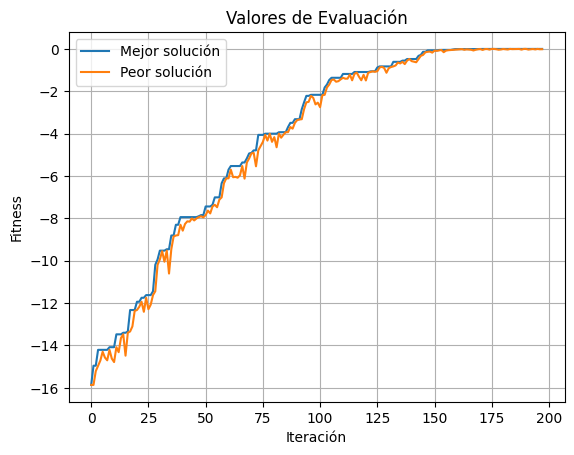

In [6]:
import math
def f(X_vars):
    return -sum( [xi**2 for xi in X_vars] )

bounds_F = [(-5,5), (-5,5)]

# Punto inicial aleatorio
x0_F = [random.uniform(b[0], b[1]) for b in bounds_F]

max_eps_F = 0.2
cant_iterac_F = 20
resolution_grafico_F = 0.1

X_mejor_F, fX_mejor_F, Trace_R_F, Trace_X_F, Trace_X_mejor_F, Trace_f_F = HillClimbing(
    f, x0_F, max_eps_F, bounds_F, cant_iterac_F)

print(f"Punto inicial: {[round(x, 2) for x in x0_F]}")
print(f"Solución final: {[round(x, 2) for x in X_mejor_F]}")
print(f"Fitness alcanzado: {round(fX_mejor_F, 4)}")
print(f"Iteraciones totales: {len(Trace_X_F) - 1}")

# Gráficos
graficarCaminata(f, Trace_X_mejor_F, bounds_F, resolution_grafico_F)
graficarEvolucionFitness(Trace_f_F)

It.1: [3.54] -> -0.8303
It.2: [3.54] -> -0.8226
It.3: [3.54] -> -0.819
It.6: [3.58] -> -0.7653
It.7: [3.62] -> -0.7016
It.8: [3.66] -> -0.6475
It.9: [3.68] -> -0.6118
It.12: [3.72] -> -0.5338
It.13: [3.74] -> -0.5108
It.14: [3.75] -> -0.4928
It.15: [3.75] -> -0.4815
It.19: [3.76] -> -0.4661
It.20: [3.77] -> -0.4571
It.21: [3.8] -> -0.3942
It.22: [3.81] -> -0.3694
It.23: [3.82] -> -0.3544
It.28: [3.83] -> -0.3421
It.32: [3.88] -> -0.2524
It.33: [3.9] -> -0.2113
It.34: [3.93] -> -0.1453
It.35: [3.94] -> -0.137
It.36: [3.94] -> -0.1239
It.37: [3.95] -> -0.1063
It.39: [3.97] -> -0.0699
It.40: [3.98] -> -0.0444
It.41: [4.0] -> -0.0177
It.43: [4.04] -> 0.0686
It.44: [4.08] -> 0.1426
It.46: [4.13] -> 0.2237
It.49: [4.16] -> 0.2814
It.51: [4.17] -> 0.2933
It.52: [4.21] -> 0.362
It.54: [4.25] -> 0.4215
It.56: [4.26] -> 0.4352
It.57: [4.28] -> 0.46
It.58: [4.31] -> 0.5111
It.60: [4.36] -> 0.5742
It.61: [4.38] -> 0.5942
It.62: [4.39] -> 0.6062
It.63: [4.41] -> 0.6251
It.66: [4.41] -> 0.6288
It.67

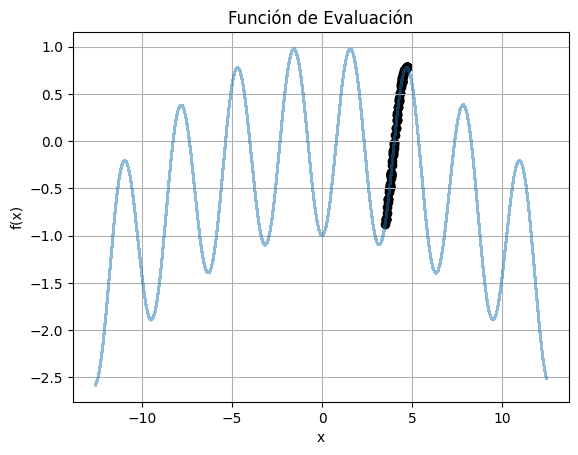

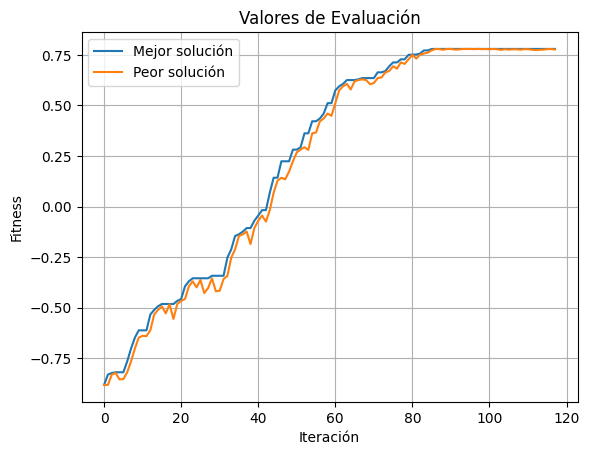

In [7]:
import math
def g(X_vars):
    return -0.01 * sum([xi**2 for xi in X_vars]) - sum([math.cos(2*xi) for xi in X_vars])

bounds_g = [(-4 * math.pi, 4 * math.pi)]

# Punto inicial aleatorio
x0_g = [random.uniform(bounds_g[0][0], bounds_g[0][1])]

max_eps_g = 0.05
cant_iterac_g = 30
resolution_grafico = 0.1

X_mejor_g, fX_mejor_g, Trace_R_g, Trace_X_g, Trace_X_mejor_g, Trace_f_g = HillClimbing(
    g, x0_g, max_eps_g, bounds_g, cant_iterac_g
)

print(f"Punto inicial: {[round(x, 2) for x in x0_g]}")
print(f"Solución final: {[round(x, 2) for x in X_mejor_g]}")
print(f"Fitness alcanzado: {round(fX_mejor_g, 4)}")
print(f"Iteraciones totales: {len(Trace_X_g) - 1}")

# Gráficos
graficarCaminata(g, Trace_X_mejor_g, bounds_g, resolution_grafico)
graficarEvolucionFitness(Trace_f_g)

It.2: [9.06, -0.48] -> -2.1448
It.5: [9.06, -0.49] -> -2.1347
It.7: [9.07, -0.49] -> -2.1308
It.13: [9.03, -0.54] -> -2.0023
It.14: [9.0, -0.6] -> -1.827
It.15: [8.98, -0.6] -> -1.8067
It.18: [8.99, -0.61] -> -1.7972
It.20: [8.96, -0.66] -> -1.6666
It.23: [8.93, -0.63] -> -1.6584
It.24: [8.93, -0.63] -> -1.6574
It.26: [8.95, -0.68] -> -1.5968
It.27: [8.95, -0.68] -> -1.5947
It.28: [8.97, -0.72] -> -1.5647
It.30: [9.02, -0.76] -> -1.5515
It.33: [8.98, -0.78] -> -1.4493
It.35: [8.96, -0.83] -> -1.306
It.37: [8.91, -0.88] -> -1.1301
It.45: [8.86, -0.94] -> -0.9272
It.46: [8.89, -1.0] -> -0.8688
It.47: [8.86, -1.05] -> -0.7098
It.51: [8.84, -1.11] -> -0.5756
It.52: [8.77, -1.1] -> -0.4546
It.57: [8.76, -1.09] -> -0.4354
It.58: [8.76, -1.15] -> -0.3515
It.60: [8.76, -1.15] -> -0.3449
It.62: [8.72, -1.21] -> -0.1739
It.71: [8.65, -1.2] -> -0.0506
It.72: [8.6, -1.16] -> 0.0081
It.73: [8.57, -1.22] -> 0.1476
It.75: [8.52, -1.2] -> 0.241
It.76: [8.51, -1.25] -> 0.3168
It.77: [8.51, -1.29] -> 0.

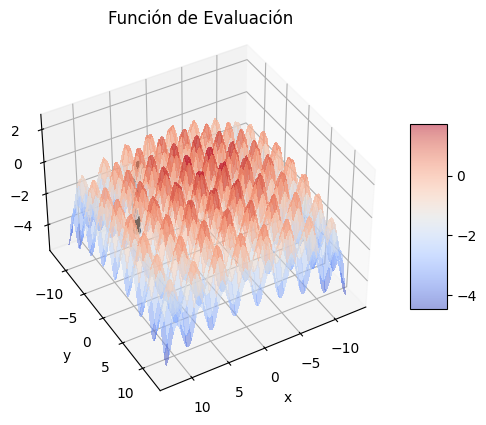

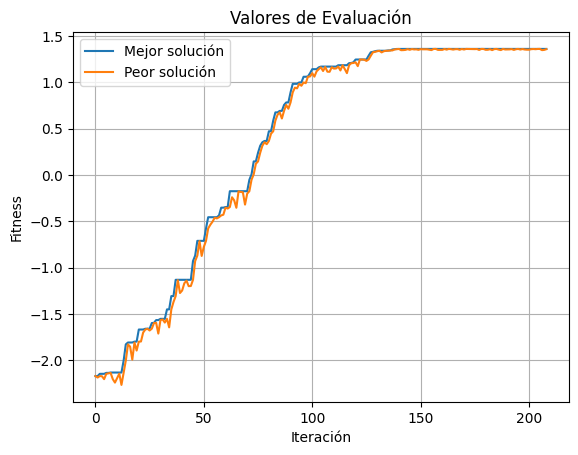

In [ ]:
import math

def G(X_vars):
    return -0.01 * sum([xi**2 for xi in X_vars]) - sum([math.cos(2*xi) for xi in X_vars])

bounds_G = [(-4*math.pi, 4*math.pi) for i in range (2)]

# Punto inicial aleatorio
x0_G = [random.uniform(b[0], b[1]) for b in bounds_G]

max_eps_G = 0.08
cant_iterac_G = 50
resolution_grafico_G = 0.1

X_mejor_G, fX_mejor_G, Trace_R_G, Trace_X_G, Trace_X_mejor_G, Trace_f_G = HillClimbing(
    G, x0_G, max_eps_G, bounds_G, cant_iterac_G
)

print(f"Punto inicial: {[round(x, 2) for x in x0_G]}")
print(f"Solución final: {[round(x, 2) for x in X_mejor_G]}")
print(f"Fitness alcanzado: {round(fX_mejor_G, 4)}")
print(f"Iteraciones totales: {len(Trace_X_G) - 1}")

# Gráficos
graficarCaminata(G, Trace_X_mejor_G, bounds_G, resolution_grafico_G)
graficarEvolucionFitness(Trace_f_G)

In [8]:
def fitness_R3(X_vars):
    # Para una funcion en R3 (entrada de 2 variables, salida 1 variable)
    # X_vars será una lista de 2 elementos, por ejemplo [x, y]
    x = X_vars[0]
    y = X_vars[1]

    # Ejemplo: Una paraboloide elíptica invertida para encontrar un máximo
    return -(x**2 + y**2)

# Demostración del uso de la función
# Por ejemplo, para un punto (1, 2):
point = [1, 2]
value = fitness_R3(point)
print(f"El valor de fitness para el punto {point} es: {value}")

# Y para el punto (0,0) (el máximo de esta función específica)
point_max = [0, 0]
value_max = fitness_R3(point_max)
print(f"El valor de fitness para el punto {point_max} es: {value_max}")

El valor de fitness para el punto [1, 2] es: -5
El valor de fitness para el punto [0, 0] es: 0


### ***Actividad complementaria:*** Gráficos de puntos aleatorios y modificaciones necesarias para hacer los puntos de avance en Hill Climbing

En esta actividad complementaria en primera situación hicimos los gráficos, pero nos dimos cuenta que en las esquinas del circulo unitario existe mayor densidad de puntos, indepnedientemente de las muestras (N) que se grafiquen, por lo tanto eso hace que nuestros números aleatorios tengan un pequeño sesgo.
Por ello hicimos un segundo código con la misma actividad, corrigiendo el sesgo.

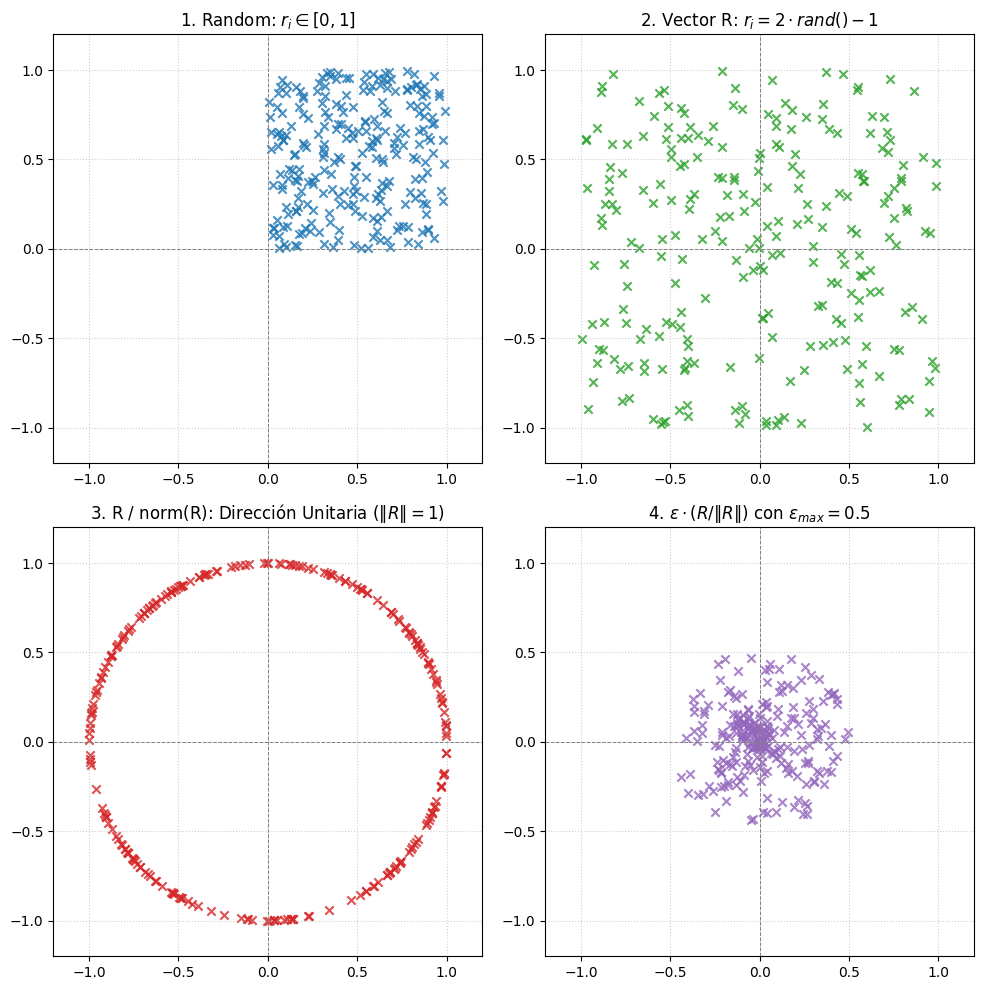

In [20]:
import random
import math
import matplotlib.pyplot as plt

# Cantidad de muestras a graficar
N = 250
max_eps = 0.5

# 1. Random puro: r_i = rand() en [0, 1]
puntos_random = [(random.random(), random.random()) for _ in range(N)]

# 2. Vector R centrado: r_i = 2 * rand() - 1 en [-1, 1]
puntos_R = [(2 * random.random() - 1, 2 * random.random() - 1) for _ in range(N)]

# 3. R / norm(R): Vector de avance normalizado
puntos_R_norm = []
for r1, r2 in puntos_R:
    norm = math.sqrt(r1**2 + r2**2)
    if norm > 0:
        puntos_R_norm.append((r1 / norm, r2 / norm))
    else:
        puntos_R_norm.append((0.0, 0.0))

# 4. E = random * E_max aplicado a la dirección unitaria
puntos_E = []
for u1, u2 in puntos_R_norm:
    eps = random.uniform(0, max_eps)
    puntos_E.append((eps * u1, eps * u2))

# ==========================================
# Configuración visual de las gráficas
# ==========================================
fig, axs = plt.subplots(2, 2, figsize=(10, 10))

# Gráfico 1: Random puro [0, 1] x [0, 1]
x1, y1 = zip(*puntos_random)
axs[0, 0].scatter(x1, y1, marker="x", color="tab:blue", alpha=0.8)
axs[0, 0].set_title(r"1. Random: $r_i \in [0, 1]$")
axs[0, 0].set_xlim(-1.2, 1.2)
axs[0, 0].set_ylim(-1.2, 1.2)
axs[0, 0].axhline(0, color="gray", linestyle="--", linewidth=0.7)
axs[0, 0].axvline(0, color="gray", linestyle="--", linewidth=0.7)
axs[0, 0].grid(True, linestyle=":", alpha=0.6)
axs[0, 0].set_aspect('equal')

# Gráfico 2: Vector R centrado [-1, 1] x [-1, 1]
x2, y2 = zip(*puntos_R)
axs[0, 1].scatter(x2, y2, marker="x", color="tab:green", alpha=0.8)
axs[0, 1].set_title(r"2. Vector R: $r_i = 2 \cdot rand() - 1$")
axs[0, 1].set_xlim(-1.2, 1.2)
axs[0, 1].set_ylim(-1.2, 1.2)
axs[0, 1].axhline(0, color="gray", linestyle="--", linewidth=0.7)
axs[0, 1].axvline(0, color="gray", linestyle="--", linewidth=0.7)
axs[0, 1].grid(True, linestyle=":", alpha=0.6)
axs[0, 1].set_aspect('equal')

# Gráfico 3: R / norm(R) (Esfera / Circunferencia Unitaria)
x3, y3 = zip(*puntos_R_norm)
axs[1, 0].scatter(x3, y3, marker="x", color="tab:red", alpha=0.8)
axs[1, 0].set_title(r"3. R / norm(R): Dirección Unitaria ($\|R\| = 1$)")
axs[1, 0].set_xlim(-1.2, 1.2)
axs[1, 0].set_ylim(-1.2, 1.2)
axs[1, 0].axhline(0, color="gray", linestyle="--", linewidth=0.7)
axs[1, 0].axvline(0, color="gray", linestyle="--", linewidth=0.7)
axs[1, 0].grid(True, linestyle=":", alpha=0.6)
axs[1, 0].set_aspect('equal')

# Gráfico 4: E = random * E_max (Círculo de radio max_eps)
x4, y4 = zip(*puntos_E)
axs[1, 1].scatter(x4, y4, marker="x", color="tab:purple", alpha=0.8)
axs[1, 1].set_title(rf"4. $\epsilon \cdot (R / \|R\|)$ con $\epsilon_{{max}} = {max_eps}$")
axs[1, 1].set_xlim(-1.2, 1.2)
axs[1, 1].set_ylim(-1.2, 1.2)
axs[1, 1].axhline(0, color="gray", linestyle="--", linewidth=0.7)
axs[1, 1].axvline(0, color="gray", linestyle="--", linewidth=0.7)
axs[1, 1].grid(True, linestyle=":", alpha=0.6)
axs[1, 1].set_aspect('equal')

plt.tight_layout()
plt.show()

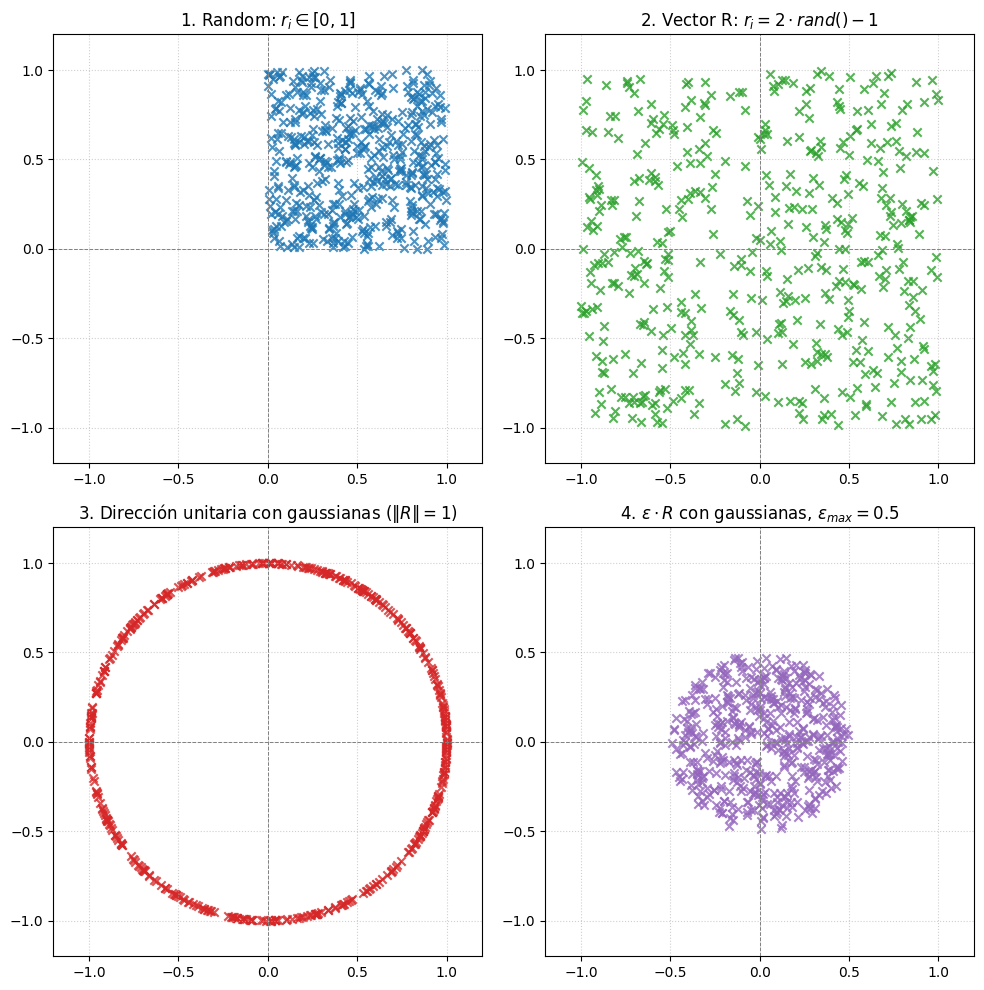

In [17]:
import random
import math
import matplotlib.pyplot as plt


# Cantidad de muestras a graficar
N = 250
max_eps = 0.5


# 1. Random puro: r_i = rand() en [0, 1]
puntos_random = [(random.random(), random.random()) for _ in range(N)]


# 2. Vector R centrado: r_i = 2 * rand() - 1 en [-1, 1]
puntos_R = [(2 * random.random() - 1, 2 * random.random() - 1) for _ in range(N)]


# 3. Dirección unitaria SIN sesgo
# En vez de normalizar puntos de un cuadrado, generamos un ángulo uniforme
puntos_R_norm = []
for _ in range(N):
    theta = random.uniform(0, 2 * math.pi)
    puntos_R_norm.append((math.cos(theta), math.sin(theta)))


# 4. E = epsilon * dirección unitaria SIN sesgo en el disco
puntos_E = []
for u1, u2 in puntos_R_norm:
    eps = max_eps * math.sqrt(random.random())
    puntos_E.append((eps * u1, eps * u2))


# ==========================================
# Configuración visual de las gráficas
# ==========================================
fig, axs = plt.subplots(2, 2, figsize=(10, 10))


# Gráfico 1: Random puro [0, 1] x [0, 1]
x1, y1 = zip(*puntos_random)
axs[0, 0].scatter(x1, y1, marker="x", color="tab:blue", alpha=0.8)
axs[0, 0].set_title(r"1. Random: $r_i \in [0, 1]$")
axs[0, 0].set_xlim(-1.2, 1.2)
axs[0, 0].set_ylim(-1.2, 1.2)
axs[0, 0].axhline(0, color="gray", linestyle="--", linewidth=0.7)
axs[0, 0].axvline(0, color="gray", linestyle="--", linewidth=0.7)
axs[0, 0].grid(True, linestyle=":", alpha=0.6)
axs[0, 0].set_aspect('equal')


# Gráfico 2: Vector R centrado [-1, 1] x [-1, 1]
x2, y2 = zip(*puntos_R)
axs[0, 1].scatter(x2, y2, marker="x", color="tab:green", alpha=0.8)
axs[0, 1].set_title(r"2. Vector R: $r_i = 2 \cdot rand() - 1$")
axs[0, 1].set_xlim(-1.2, 1.2)
axs[0, 1].set_ylim(-1.2, 1.2)
axs[0, 1].axhline(0, color="gray", linestyle="--", linewidth=0.7)
axs[0, 1].axvline(0, color="gray", linestyle="--", linewidth=0.7)
axs[0, 1].grid(True, linestyle=":", alpha=0.6)
axs[0, 1].set_aspect('equal')


# Gráfico 3: Dirección unitaria sin sesgo
x3, y3 = zip(*puntos_R_norm)
axs[1, 0].scatter(x3, y3, marker="x", color="tab:red", alpha=0.8)
axs[1, 0].set_title(r"3. Dirección unitaria sin sesgo ($\|R\| = 1$)")
axs[1, 0].set_xlim(-1.2, 1.2)
axs[1, 0].set_ylim(-1.2, 1.2)
axs[1, 0].axhline(0, color="gray", linestyle="--", linewidth=0.7)
axs[1, 0].axvline(0, color="gray", linestyle="--", linewidth=0.7)
axs[1, 0].grid(True, linestyle=":", alpha=0.6)
axs[1, 0].set_aspect('equal')


# Gráfico 4: Paso sin sesgo dentro del círculo
x4, y4 = zip(*puntos_E)
axs[1, 1].scatter(x4, y4, marker="x", color="tab:purple", alpha=0.8)
axs[1, 1].set_title(rf"4. $\epsilon \cdot R$ sin sesgo, $\epsilon_{{max}} = {max_eps}$")
axs[1, 1].set_xlim(-1.2, 1.2)
axs[1, 1].set_ylim(-1.2, 1.2)
axs[1, 1].axhline(0, color="gray", linestyle="--", linewidth=0.7)
axs[1, 1].axvline(0, color="gray", linestyle="--", linewidth=0.7)
axs[1, 1].grid(True, linestyle=":", alpha=0.6)
axs[1, 1].set_aspect('equal')


plt.tight_layout()
plt.show()

# Resolución por normalización gaussiana

Cuando salimos de $(R^2)$, generar una dirección uniforme mediante un único ángulo deja de ser práctico, ya que en dimensiones mayores la parametrización se vuelve más compleja. En esos casos, una alternativa natural es construir un vector cuyas componentes sean variables aleatorias gaussianas independientes con la misma distribución y luego normalizarlo.

La idea importante es que, aunque cada componente individual tenga una distribución normal centrada en cero, el vector completo no privilegia ninguna dirección del espacio. Por esa simetría, al dividir el vector por su norma obtenemos una dirección unitaria sin sesgo, es decir, uniformemente distribuida sobre la esfera unitaria correspondiente.

En Python, `random.gauss(0, 1)` genera valores con distribución normal estándar; en este contexto, “gaussiana” y “normal” refieren a la misma familia de distribuciones. Lo importante para evitar sesgo es que todas las componentes se generen de forma independiente y con los mismos parámetros.

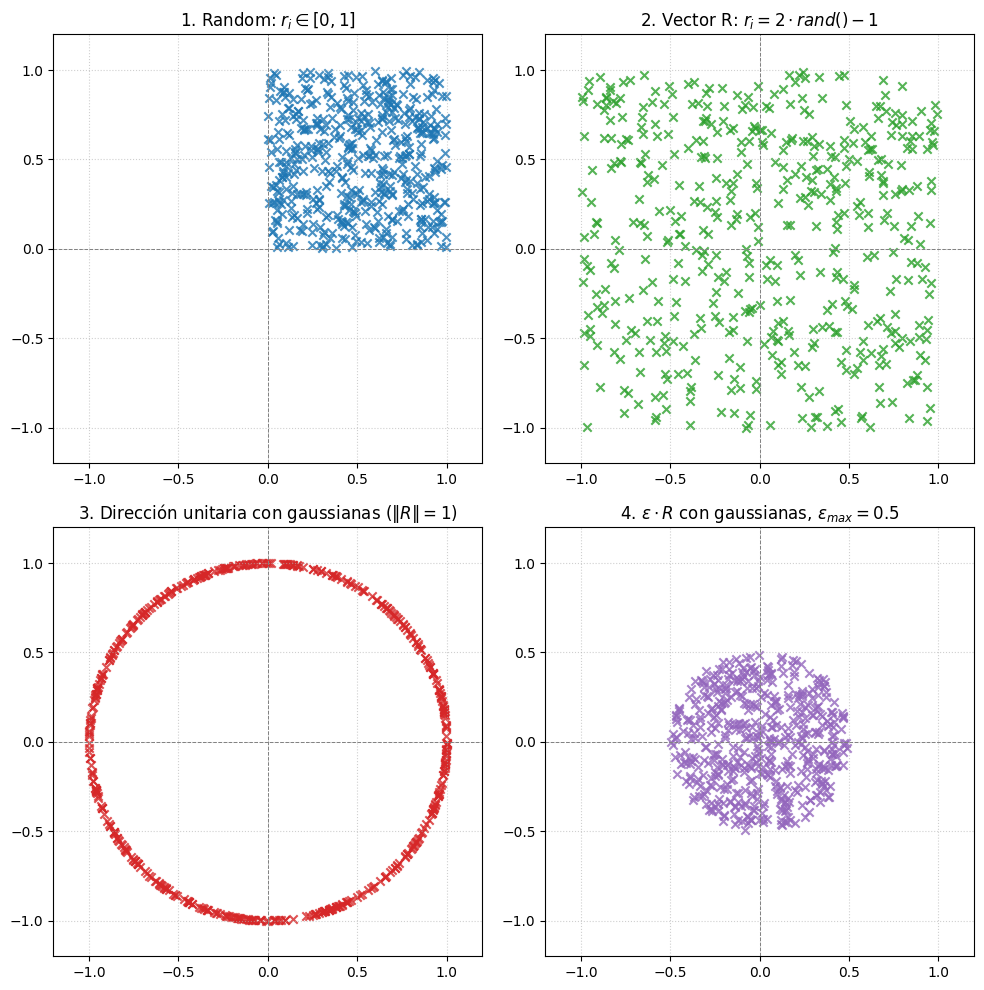

In [18]:
import random
import math
import matplotlib.pyplot as plt


# Cantidad de muestras a graficar
N = 500
max_eps = 0.5


# 1. Random puro: r_i = rand() en [0, 1]
puntos_random = [(random.random(), random.random()) for _ in range(N)]


# 2. Vector R centrado: r_i = 2 * rand() - 1 en [-1, 1]
puntos_R = [(2 * random.random() - 1, 2 * random.random() - 1) for _ in range(N)]


# 3. Dirección unitaria SIN sesgo usando gaussianas
# Este paso corrige hacia dónde apunta el vector.
puntos_R_norm = []
for _ in range(N):
    g1 = random.gauss(0, 1)
    g2 = random.gauss(0, 1)

    norm = math.sqrt(g1**2 + g2**2)

    if norm > 0:
        puntos_R_norm.append((g1 / norm, g2 / norm))
    else:
        puntos_R_norm.append((0.0, 0.0))


# 4. E = epsilon * dirección unitaria SIN sesgo en el disco
# Este paso corrige a qué distancia se ubica el nuevo punto.
puntos_E = []
for u1, u2 in puntos_R_norm:
    eps = max_eps * math.sqrt(random.random())
    puntos_E.append((eps * u1, eps * u2))


# ==========================================
# Configuración visual de las gráficas
# ==========================================
fig, axs = plt.subplots(2, 2, figsize=(10, 10))


# Gráfico 1: Random puro [0, 1] x [0, 1]
x1, y1 = zip(*puntos_random)
axs[0, 0].scatter(x1, y1, marker="x", color="tab:blue", alpha=0.8)
axs[0, 0].set_title(r"1. Random: $r_i \in [0, 1]$")
axs[0, 0].set_xlim(-1.2, 1.2)
axs[0, 0].set_ylim(-1.2, 1.2)
axs[0, 0].axhline(0, color="gray", linestyle="--", linewidth=0.7)
axs[0, 0].axvline(0, color="gray", linestyle="--", linewidth=0.7)
axs[0, 0].grid(True, linestyle=":", alpha=0.6)
axs[0, 0].set_aspect('equal')


# Gráfico 2: Vector R centrado [-1, 1] x [-1, 1]
x2, y2 = zip(*puntos_R)
axs[0, 1].scatter(x2, y2, marker="x", color="tab:green", alpha=0.8)
axs[0, 1].set_title(r"2. Vector R: $r_i = 2 \cdot rand() - 1$")
axs[0, 1].set_xlim(-1.2, 1.2)
axs[0, 1].set_ylim(-1.2, 1.2)
axs[0, 1].axhline(0, color="gray", linestyle="--", linewidth=0.7)
axs[0, 1].axvline(0, color="gray", linestyle="--", linewidth=0.7)
axs[0, 1].grid(True, linestyle=":", alpha=0.6)
axs[0, 1].set_aspect('equal')


# Gráfico 3: Dirección unitaria sin sesgo con gaussianas
x3, y3 = zip(*puntos_R_norm)
axs[1, 0].scatter(x3, y3, marker="x", color="tab:red", alpha=0.8)
axs[1, 0].set_title(r"3. Dirección unitaria con gaussianas ($\|R\| = 1$)")
axs[1, 0].set_xlim(-1.2, 1.2)
axs[1, 0].set_ylim(-1.2, 1.2)
axs[1, 0].axhline(0, color="gray", linestyle="--", linewidth=0.7)
axs[1, 0].axvline(0, color="gray", linestyle="--", linewidth=0.7)
axs[1, 0].grid(True, linestyle=":", alpha=0.6)
axs[1, 0].set_aspect('equal')


# Gráfico 4: Paso sin sesgo dentro del círculo
x4, y4 = zip(*puntos_E)
axs[1, 1].scatter(x4, y4, marker="x", color="tab:purple", alpha=0.8)
axs[1, 1].set_title(rf"4. $\epsilon \cdot R$ con gaussianas, $\epsilon_{{max}} = {max_eps}$")
axs[1, 1].set_xlim(-1.2, 1.2)
axs[1, 1].set_ylim(-1.2, 1.2)
axs[1, 1].axhline(0, color="gray", linestyle="--", linewidth=0.7)
axs[1, 1].axvline(0, color="gray", linestyle="--", linewidth=0.7)
axs[1, 1].grid(True, linestyle=":", alpha=0.6)
axs[1, 1].set_aspect('equal')


plt.tight_layout()
plt.show()

## Conclusiones

Tras el desarrollo y experimentación de este TP nuestras conclusiones son:

### 1. Desempeño del algoritmo Hill Climbing

Al probar Hill Climbing vimos que funciona bien cuando la función tiene un solo máximo, como en la parábola: sin importar demasiado desde dónde empiece, termina acercándose al mejor punto.

En cambio, cuando la función tiene varios máximos, el resultado depende mucho del punto inicial. El algoritmo va mejorando de a poco, pero puede quedarse en un máximo local y no llegar al máximo global, porque no acepta moverse a puntos peores para explorar otras zonas debido a que es un algoritmo Greedy.

También pudimos ver gráficamente que el tamaño del paso, definido por `max_eps`, influye mucho en el resultado. Si el paso es muy grande, el algoritmo puede saltearse mejoras cercanas o tener dificultades para ajustarse al llegar a un máximo. Por otro lado, si el paso es muy chico, logra movimientos más precisos pero puede tardar muchas más iteraciones en avanzar. Por eso es importante elegir un valor equilibrado según la función que se quiere optimizar.

### 2. Corrección sobre la generación de números aleatorios
Como vimos en el TP N.° 1, `random.random()` genera valores uniformes entre 0 y 1, por lo que el problema no estaba en el generador utilizado. Al analizar los gráficos y considerar los comentarios vistos en clase, vimos que el sesgo aparecía en la forma de transformar esos valores para construir el vector de avance.

Primero se generaban puntos dentro de un cuadrado y luego se los normalizaba para llevarlos a la circunferencia. Esto hacía que las direcciones diagonales aparecieran más veces que las direcciones cercanas a los ejes, por lo que la exploración no era completamente uniforme.

Para corregirlo en el paso 3, generamos el vector de dirección a partir de valores gaussianos independientes y luego lo normalizamos. También probamos una alternativa usando seno y coseno de un ángulo aleatorio; en dos dimensiones ambas opciones permiten distribuir los puntos de forma uniforme sobre la circunferencia.

Además en el paso 4, modificamos la forma de generar el tamaño del paso. Antes se elegía una distancia uniforme entre cero y `max_eps`, lo que concentraba más puntos cerca del centro. Al usar la raíz cuadrada del valor aleatorio, los puntos se distribuyen de forma más uniforme dentro del círculo de exploración.

De esta manera, la búsqueda sigue siendo aleatoria, pero ahora explora de forma más equilibrada alrededor de la solución actual. Esto no garantiza encontrar el máximo global, ya que Hill Climbing puede quedar atrapado en un óptimo local, pero evita que la generación de puntos favorezca ciertas direcciones o zonas.

